In [ ]:
#!pip install postcell

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 53.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 46.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 kB 4.2 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git

!git status

/content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [ ]:
%reload_ext postcell
%postcell register

PostCell loaded
Loading config file from /content/drive/MyDrive/2026/Markoding/Week-1-pi-integrasi-ai.git/postcell.conf
Registered user Fara_Olivia at https://postcell.io/post_cell


## Bagian A — OpenCV: memproses foto sampah

In [ ]:
!pip -q install opencv-python-headless pillow matplotlib

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

print("Versi OpenCV:", cv2.__version__)

Versi OpenCV: 5.0.0


### 1. Upload Foto Sampah

Saving segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui.jpeg to segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui.jpeg
Dimensi gambar: (667, 1000, 3)


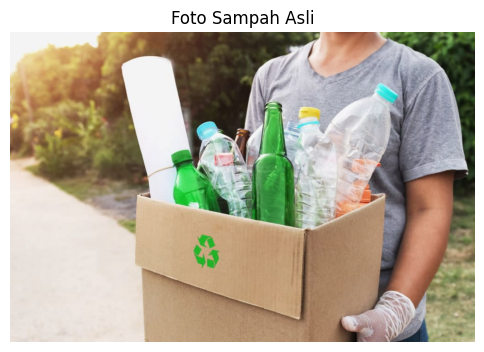

In [ ]:
uploaded = files.upload()
filename = next(iter(uploaded))

image_bgr = cv2.imread(filename)

if image_bgr is None:
    raise ValueError("Gambar tidak berhasil dibaca.")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print("Dimensi gambar:", image_bgr.shape)

plt.figure(figsize=(6, 5))
plt.imshow(image_rgb)
plt.title("Foto Sampah Asli")
plt.axis("off")
plt.show()

### 2. Grayscale, resize, dan deteksi tepi

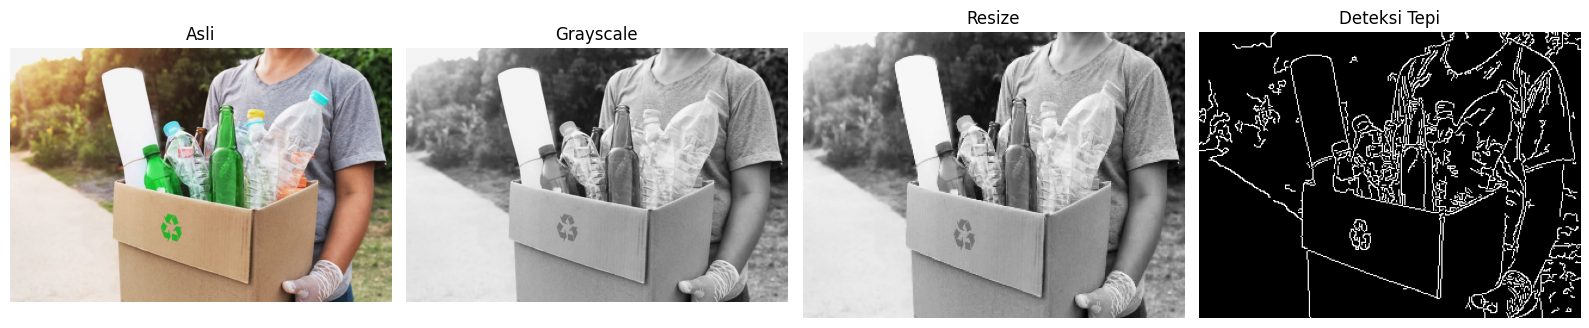

In [ ]:
%%postcell RGB
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

resized = cv2.resize(gray, (320, 240))

edges = cv2.Canny(resized, 100, 200)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image_rgb)
axes[0].set_title("Asli")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")

axes[2].imshow(resized, cmap="gray")
axes[2].set_title("Resize")

axes[3].imshow(edges, cmap="gray")
axes[3].set_title("Deteksi Tepi")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Apakah deteksi tepi dapat memberi tahu kita bahwa objek dalam gambar adalah botol plastik?

# Klasifikasi sampah menggunakan AI

Kita akan menggunakan dataset TrashNet yang berisi enam kelas dan 2.527 gambar: kaca, kertas, kardus, plastik, logam, dan sampah umum.

Model akan belajar memprediksi kelas utama untuk sebuah gambar. Kita menggunakan transfer learning, yaitu memanfaatkan model MobileNetV2 yang sudah dilatih pada dataset gambar umum, kemudian menyesuaikan bagian klasifikasinya untuk enam kategori sampah.

In [ ]:
!pip -q install kagglehub

In [ ]:
%%postcell DownloadDataKaggle
import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download("mostafaabla/garbage-classification")
)

print("Dataset tersimpan di:", dataset_path)

# Tampilkan struktur folder untuk memeriksa lokasi gambar
for path in list(dataset_path.rglob("*"))[:30]:
    print(path)

100%|██████████| 239M/239M [00:01<00:00, 154MB/s]

Extracting files...


Dataset tersimpan di: /root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification/biological
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification/plastic
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification/cardboard
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification/metal
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification/clothes
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification/white-glass
/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification/brown-glass
/root/.cache/kagglehub/da

Kalau tidak muncul bisa download di https://www.kaggle.com/datasets/mostafaabla/garbage-classification$0

In [ ]:
from pathlib import Path

known_classes = {
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
}

candidates = []

for folder in [dataset_path, *dataset_path.rglob("*")]:
    if not folder.is_dir():
        continue

    child_dirs = {
        p.name.lower().strip()
        for p in folder.iterdir()
        if p.is_dir()
    }

    matched = child_dirs & known_classes

    if len(matched) >= 4:
        candidates.append((folder, matched))

if not candidates:
    raise FileNotFoundError(
        "Folder kelas belum ditemukan. Periksa struktur dataset "
        "dan tentukan path folder yang berisi subfolder kategori."
    )

data_dir, matched_classes = max(
    candidates, key=lambda item: len(item[1])
)

print("Folder dataset:", data_dir)
print("Kategori ditemukan:", sorted(matched_classes))

Folder dataset: /root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification
Kategori ditemukan: ['cardboard', 'metal', 'paper', 'plastic', 'trash']


In [ ]:
import tensorflow as tf

SEED = 42
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Kelas:", class_names)
print("Jumlah kelas:", len(class_names))

Found 15515 files belonging to 12 classes.
Using 12412 files for training.
Found 15515 files belonging to 12 classes.
Using 3103 files for validation.
Kelas: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Jumlah kelas: 12


### Melihat Gambar dan Label

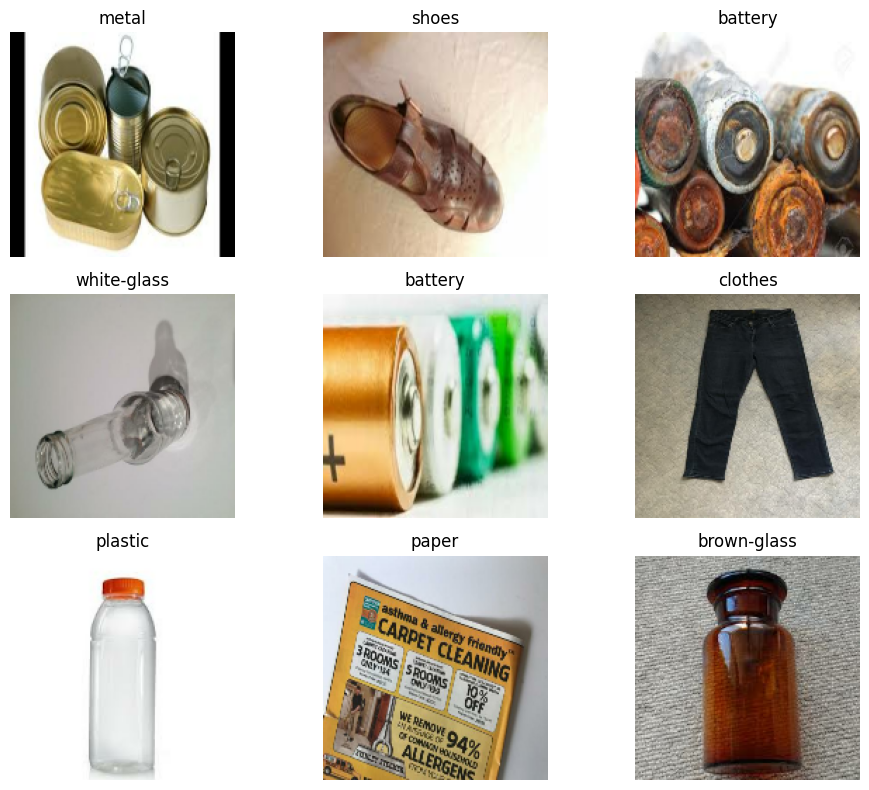

In [ ]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

### Membuat model klasifikasi

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

num_classes = len(class_names)

# Model pretrained, tanpa lapisan klasifikasi ImageNet
base_model = keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

# Pada tahap awal, bekukan bobot model pretrained
base_model.trainable = False

inputs = keras.Input(shape=(160, 160, 3))

# MobileNetV2 mengharapkan nilai piksel pada rentang -1 hingga 1
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 15,372 (60.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Penjelasan sederhana:
- MobileNetV2 mengekstraksi pola visual seperti bentuk dan tekstur.
- GlobalAveragePooling2D merangkum fitur visual.
- Dense + Softmax menghasilkan skor prediksi untuk setiap kategori.
- Kita membekukan model dasar agar pelatihan lebih ringan untuk demonstrasi.

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1
)

388/388 ━━━━━━━━━━━━━━━━━━━━ 348s 882ms/step - accuracy: 0.8459 - loss: 0.4973 - val_accuracy: 0.9275 - val_loss: 0.2361


1 epoch cukup untuk demonstrasi awal, tetapi tidak menjamin akurasi yang tinggi. Waktu pelatihan bergantung pada perangkat yang digunakan dan jumlah gambar.

### Melihat hasil training

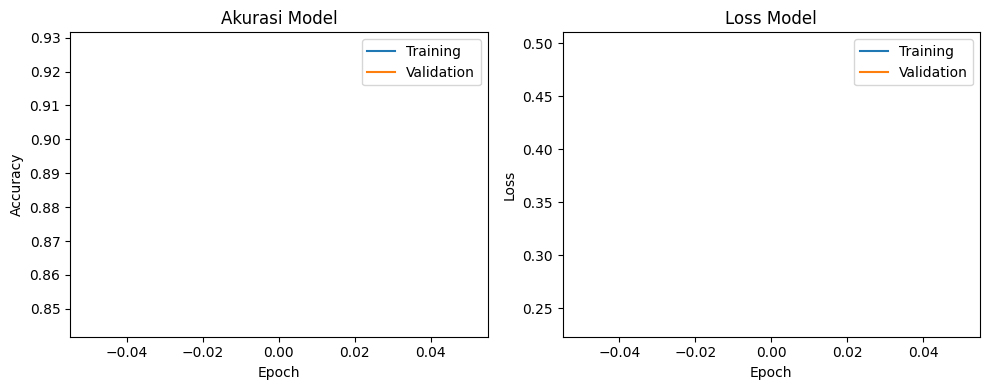

In [ ]:
%%postcell MelihatHasilTraining
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Akurasi Model")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss Model")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Kita perlu membandingkan akurasi training dan validation. Jika akurasi training jauh lebih tinggi, model mungkin mengalami overfitting. Akurasi validasi juga belum sama dengan performa pada foto sampah di dunia nyata.

Saving segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui.jpeg to segudang-manfaat-bank-sampah-dan-cara-kerjanya-yang-perlu-diketahui (1).jpeg


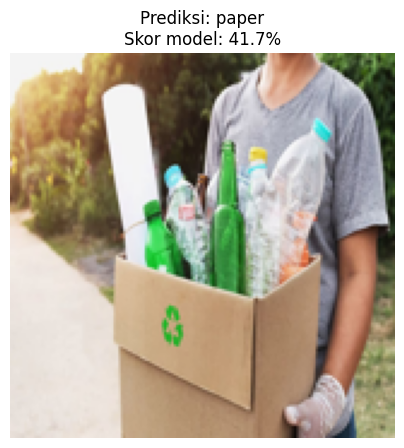

Kategori prediksi: paper
Skor prediksi: 41.7%


In [ ]:
uploaded = files.upload()
test_filename = next(iter(uploaded))

test_image = Image.open(test_filename).convert("RGB")
test_image = test_image.resize(IMG_SIZE)

image_array = np.array(test_image, dtype=np.float32)
image_batch = np.expand_dims(image_array, axis=0)

probabilities = model.predict(image_batch, verbose=0)[0]

predicted_index = int(np.argmax(probabilities))
predicted_class = class_names[predicted_index]
confidence = float(probabilities[predicted_index])

plt.figure(figsize=(5, 5))
plt.imshow(test_image)
plt.title(
    f"Prediksi: {predicted_class}\n"
    f"Skor model: {confidence:.1%}"
)
plt.axis("off")
plt.show()

print("Kategori prediksi:", predicted_class)
print("Skor prediksi:", f"{confidence:.1%}")